# 🏥 Liver-Tumor Segmentation - 2.5D UNet [OPTIMISE v6]
- Dataset: target multiclass unifie (0=bg, 1=foie, 2=tumeur)
- Lecture partielle nii.dataobj (pas d OOM RAM)
- AMP Mixed Precision + batch=12
- Sauvegarde checkpoint Google Drive (persistant apres session)

## 📋 TABLE DES MATIÈRES
1. **📦 Imports** - bibliothèques PyTorch, nibabel, matplotlib
2. **📂 Chargement des données** - localiser datasets LITS
3. **🔴 Fonction de Perte** - CEDiceLoss (CrossEntropy + Dice)
4. **🧠 Architecture UNet** - modèle 2.5D
5. **📊 Classe Dataset** - LiverTumorDataset avec preprocessing
6. **🔀 Création DataLoaders** - split 70/15/15 train/val/test
7. **🎨 Visualisation des données** - affichage exemples
8. **🔍 Optimisation Hyperparamètres** - Optuna tuning
9. **🚀 Entraînement** - training loop 10 epochs AMP
10. **🎯 Pipeline d'Inférence** - multiclass avec seuils
11. **📁 Prédiction 3D** - inference batch volumes
12. **📈 Évaluation** - métriques test set (Dice, IoU, F1)
13. **🖼️ Visualisation Prédictions** - overlays pred vs GT
14. **📊 Résultats et Graphiques** - courbes, matrice confusion

# SECTION 1: IMPORTS


In [1]:
# %pip install torch numpy pandas matplotlib seaborn nibabel tqdm

In [4]:
pip install -q pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ===== CELL 2: IMPORTS =====
print("Importation des bibliothèques...")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np
import nibabel as nib
from tqdm import tqdm
import os
from pathlib import Path
import pandas as pd
from datetime import datetime

Importation des bibliothèques...


# SECTION 2: CHARGEMENT DES DONNÉES ET CREATION DU DATAFRAME
Localiser et charger les datasets LITS (volumes et segmentations) avec support .nii et .nii.gz

In [3]:
# import zipfile
# import os

# def unzip_file(zip_path, extract_to):
#     """
#     Unzips a ZIP file to the specified directory.
    
#     Args:
#         zip_path (str): Path to the ZIP file.
#         extract_to (str): Directory where files will be extracted.
#     """
#     try:
#         # Validate file existence
#         if not os.path.isfile(zip_path):
#             raise FileNotFoundError(f"ZIP file not found: {zip_path}")

#         # Ensure the output directory exists
#         os.makedirs(extract_to, exist_ok=True)

#         # Open and extract the ZIP file
#         with zipfile.ZipFile(zip_path, 'r') as zip_ref:
#             zip_ref.extractall(extract_to)
#             print(f"✅ Extracted {len(zip_ref.namelist())} files to '{extract_to}'")

#     except zipfile.BadZipFile:
#         print("❌ Error: The file is not a valid ZIP archive.")
#     except PermissionError:
#         print("❌ Error: Permission denied while accessing files.")
#     except Exception as e:
#         print(f"❌ Unexpected error: {e}")

# # Example usage
# if __name__ == "__main__":
#     zip_file_path = "../dataset.zip"       # Path to your ZIP file
#     output_directory = "dataset" # Destination folder
#     unzip_file(zip_file_path, output_directory)

In [4]:
# # ===== CELL 1: LOAD DATA (LITS DATASETS) =====
# import pandas as pd
# import nibabel as nib
# from pathlib import Path

# print("="*70)
# print("📂 CHARGEMENT DES DATASETS LITS")
# print("="*70)

# # Essai 1: Chemins directs simples
# KAGGLE_INPUT_ROOT = Path("/kaggle/input")
# if not KAGGLE_INPUT_ROOT.exists():
#     raise FileNotFoundError("/kaggle/input introuvable.")

# required_names = [
#     "liver-tumor-segmentation",
#     "liver-tumor-segmentation-part-2",
# ]

# dataset_roots = []
# for name in required_names:
#     explicit = KAGGLE_INPUT_ROOT / "datasets" / "andrewmvd" / name
#     alt = KAGGLE_INPUT_ROOT / name
#     if explicit.exists() and explicit.is_dir():
#         dataset_roots.append(explicit)
#     elif alt.exists() and alt.is_dir():
#         dataset_roots.append(alt)

# # Essai 2: Fallback - scan par nom si montage non standard
# if len(dataset_roots) < 2:
#     found_by_name = []
#     for p in KAGGLE_INPUT_ROOT.rglob("*"):
#         if p.is_dir() and p.name in required_names:
#             found_by_name.append(p)
#     for p in found_by_name:
#         if p not in dataset_roots:
#             dataset_roots.append(p)

# if len(dataset_roots) < 2:
#     visible = [str(p) for p in KAGGLE_INPUT_ROOT.iterdir() if p.is_dir()]
#     raise FileNotFoundError(
#         "Impossible de trouver les 2 datasets LiTS.\n"
#         f"Dossiers visibles: {visible}\n"
#         "Verifiez les 2 datasets dans 'Add Input'."
#     )

# dataset_roots = dataset_roots[:2]

# # Recherche robuste des fichiers (supports .nii et .nii.gz)
# def list_nii_files(root, pattern):
#     return sorted(list(Path(root).rglob(f"{pattern}.nii")) + list(Path(root).rglob(f"{pattern}.nii.gz")))

# volume_files = []
# for root in dataset_roots:
#     volume_files.extend(list_nii_files(root, "volume-*"))

# segmentation_files = []
# for root in dataset_roots:
#     segmentation_files.extend(list_nii_files(root, "segmentation-*"))

# if not volume_files:
#     raise FileNotFoundError("Aucun fichier volume-*.nii(.gz) trouve.")
# if not segmentation_files:
#     raise FileNotFoundError("Aucun fichier segmentation-*.nii(.gz) trouve.")

# # Matcher par ID
# seg_by_id = {}
# for seg in segmentation_files:
#     name = seg.name.replace(".nii.gz", "").replace(".nii", "")
#     if name.startswith("segmentation-"):
#         seg_id = name.replace("segmentation-", "")
#         seg_by_id[seg_id] = seg

# rows = []
# for vol in sorted(volume_files, key=lambda p: p.name):
#     name = vol.name.replace(".nii.gz", "").replace(".nii", "")
#     if not name.startswith("volume-"):
#         continue
#     vol_id = name.replace("volume-", "")
#     seg = seg_by_id.get(vol_id)
#     if seg is None:
#         continue
#     try:
#         numeric_id = int(vol_id)
#     except ValueError:
#         continue
#     rows.append({
#         "volume_path": str(vol),
#         "segmentation_path": str(seg),
#         "volume_id": numeric_id,
#     })

# df = pd.DataFrame(rows).sort_values("volume_id").reset_index(drop=True)
# if df.empty:
#     raise RuntimeError("Aucune paire volume-segmentation valide n'a ete trouvee.")

# print(f"\n✅ Datasets trouves:")
# for root in dataset_roots:
#     print(f"   - {root}")
# print(f"\n✅ Nombre total de paires: {len(df)}")
# print(df.head().to_string(index=False))

# sample_volume = nib.load(df.iloc[0]["volume_path"])
# sample_seg = nib.load(df.iloc[0]["segmentation_path"])
# print(f"\n✅ Shape volume exemple: {sample_volume.shape}")
# print(f"✅ Shape segmentation exemple: {sample_seg.shape}")
# print("="*70 + "\n")

In [3]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))


import glob 
# Définir les chemins
dataset_path = r"/workspace/"
segmentation_path = os.path.join(dataset_path, "segmentations")
volume_folders = [f"volume_pt{i}" for i in [1, 2, 3, 4, 5, 6, 8]]

def create_dataset_index(dataset_path, volume_folders, segmentation_path):
    """Crée un index léger de tous les volumes"""
    data_list = []
    
    for folder in volume_folders:
        folder_path = os.path.join(dataset_path, folder)
        if not os.path.exists(folder_path):
            continue
            
        volume_files = glob.glob(os.path.join(folder_path, "volume-*.nii")) # Trouve tous les fichiers volume-*.nii dans le dossier folder_path

        for volume_file in volume_files:
            volume_num = os.path.basename(volume_file).replace("volume-", "").replace(".nii", "")
            #basename(volume_file) extrait le nom du fichier à partir du chemin complet, puis replace() est utilisé pour supprimer "volume-" et ".nii" afin d'obtenir uniquement le numéro du volume.
            seg_file = os.path.join(segmentation_path, f"segmentation-{volume_num}.nii")
            #
            if os.path.exists(seg_file):
                data_list.append({
                    'volume_path': volume_file,
                    'segmentation_path': seg_file,
                    'volume_id': int(volume_num)
                })
    
    return pd.DataFrame(data_list)

# Créer l'index (très rapide, pas de preprocessing)
df = create_dataset_index(dataset_path, volume_folders, segmentation_path)
df = df.sort_values('volume_id').reset_index(drop=True)
#drop
print(f"✅ {len(df)} volumes trouvés")
print(f"📊 Index du dataset: {df.shape}")
print(f"\nPremiers volumes:")
print(df.head())

START: 15:19:38


KeyError: 'volume_id'

# 🔴 SECTION 3: FONCTION DE PERTE
Combinaison CrossEntropy + Dice Loss pour la segmentation multiclass (foie + tumeur)

In [6]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# ===== CELL 3: LOSS FUNCTIONS =====
print("="*70)
print("🔴 LOSS FUNCTIONS: CEDiceLoss + Multiclass Dice")
print("="*70)

def multiclass_dice_loss(pred, target, smooth=1.0, num_classes=3):
    """Calcule le Dice loss pour multiclass segmentation"""
    dice_total = 0.0
    pred_prob = torch.softmax(pred, dim=1)
    for c in range(num_classes):
        pred_c = pred_prob[:, c, :, :]
        target_c = (target == c).float()
        intersection = torch.sum(pred_c * target_c)
        union = torch.sum(pred_c) + torch.sum(target_c)
        dice_c = (2.0 * intersection + smooth) / (union + smooth) if union > 0 else 1.0
        dice_total += dice_c
    return 1.0 - (dice_total / num_classes)

class CEDiceLoss(nn.Module):
    """Combinaison: CrossEntropy + Dice Loss"""
    def __init__(self, weight_ce=0.5, weight_dice=0.5, num_classes=3):
        super(CEDiceLoss, self).__init__()
        self.ce = nn.CrossEntropyLoss()
        self.weight_ce = weight_ce
        self.weight_dice = weight_dice
        self.num_classes = num_classes
    
    def forward(self, pred, target):
        ce_loss_value = self.ce(pred, target)
        dice_loss_value = multiclass_dice_loss(pred, target, num_classes=self.num_classes)
        return self.weight_ce * ce_loss_value + self.weight_dice * dice_loss_value

print("✅ Loss functions chargées")

START: 15:22:21
🔴 LOSS FUNCTIONS: CEDiceLoss + Multiclass Dice
✅ Loss functions chargées


# SECTION 4: ARCHITECTURE UNET
Modèle UNet pour la segmentation 2.5D (3 canaux d'entrée, 3 classes de sortie)

In [7]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# ===== CELL 4: UNET ARCHITECTURE =====
print("="*70)
print("🧠 UNET ARCHITECTURE: Définition du modèle")
print("="*70)

class DoubleConv(nn.Module):
    """Bloc: 2 convolutions + BatchNorm + ReLU"""
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.double_conv(x)

class Down(nn.Module):
    """Bloc Downsampling: MaxPool + DoubleConv"""
    def __init__(self, in_channels, out_channels):
        super(Down, self).__init__()
        self.down = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )
    def forward(self, x):
        return self.down(x)

class Up(nn.Module):
    """Bloc Upsampling: Upsample + Concatenate + DoubleConv"""
    def __init__(self, in_channels, out_channels, bilinear=True):
        super(Up, self).__init__()
        if bilinear:
            self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        else:
            self.up = nn.ConvTranspose2d(in_channels // 2, in_channels // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels, out_channels)
    
    def forward(self, x1, x2):
        x1 = self.up(x1)
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2, diffY // 2, diffY - diffY // 2])
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)

class UNet(nn.Module):
    """UNet complet: 4 down + 4 up + skip connections"""
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        self.in_conv = DoubleConv(n_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)
        self.down4 = Down(512, 1024)
        self.up1 = Up(1024 + 512, 512)
        self.up2 = Up(512 + 256, 256)
        self.up3 = Up(256 + 128, 128)
        self.up4 = Up(128 + 64, 64)
        self.out_conv = nn.Conv2d(64, n_classes, kernel_size=1)
    
    def forward(self, x):
        x1 = self.in_conv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.out_conv(x)

print("✅ UNet architecture créée")

START: 15:22:22
🧠 UNET ARCHITECTURE: Définition du modèle
✅ UNet architecture créée


# SECTION 5: CLASSE DATASET
Classe LiverTumorDataset pour charger slices 2.5D avec preprocessing (windowing, normalization, resizing)

In [8]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# ===== CELL 5: DATASET CLASS (target multiclass unifie) =====
print("="*70)

class LiverTumorDataset(Dataset):
    def __init__(self, dataframe, slice_range=(0.2, 0.8)):
        self.df          = dataframe.reset_index(drop=True)
        self.target_size = (480, 480)
        self.slice_index = []
        self.vol_stats   = {}

        print("Construction index + calcul stats de normalisation...")
        for idx, row in tqdm(self.df.iterrows(), total=len(self.df), desc="Index"):
            nii = nib.load(row["volume_path"])
            D   = nii.shape[2]
            start_z = int(D * slice_range[0])
            end_z   = int(D * slice_range[1])
            for z in range(max(1, start_z), min(D - 1, end_z)):
                self.slice_index.append((idx, z))
            vol_clipped = np.clip(nii.get_fdata().astype(np.float32), -200, 200)
            self.vol_stats[idx] = (float(vol_clipped.min()), float(vol_clipped.max()))
            del vol_clipped

        print(f"Total slices: {len(self.slice_index)}")

    def __len__(self):
        return len(self.slice_index)

    def __getitem__(self, idx):
        df_idx, z = self.slice_index[idx]
        row = self.df.iloc[df_idx]
        v_min, v_max = self.vol_stats[df_idx]

        vol_nii = nib.load(row["volume_path"])
        seg_nii = nib.load(row["segmentation_path"])

        def read_slice(nii, zi):
            return np.array(nii.dataobj[:, :, zi], dtype=np.float32)

        def norm(s):
            s = np.clip(s, -200, 200)
            if v_max > v_min:
                return (s - v_min) / (v_max - v_min)
            return np.zeros_like(s)

        # 2.5D: 3 slices consecutives
        s = np.stack([
            norm(read_slice(vol_nii, z-1)),
            norm(read_slice(vol_nii, z  )),
            norm(read_slice(vol_nii, z+1)),
        ], axis=0).astype(np.float32)  # (3, H, W)

        # Target multiclass unifie: 0=background, 1=foie, 2=tumeur
        seg_z  = read_slice(seg_nii, z)
        target = np.zeros(seg_z.shape, dtype=np.int64)
        target[seg_z >= 1] = 1  # foie
        target[seg_z == 2] = 2  # tumeur (ecrase foie si overlap)

        H, W = s.shape[1], s.shape[2]
        if (H, W) != self.target_size:
            t = torch.from_numpy(s).unsqueeze(0)
            s = F.interpolate(t, size=self.target_size, mode="bilinear",
                              align_corners=False).squeeze(0).numpy()
            tgt = torch.from_numpy(target).unsqueeze(0).unsqueeze(0).float()
            target = F.interpolate(tgt, size=self.target_size,
                                   mode="nearest").squeeze().numpy().astype(np.int64)

        return {
            "image":  torch.from_numpy(s).float(),
            "target": torch.from_numpy(target).long(),  # (480, 480) - valeurs 0,1,2
        }

print("Dataset OK - retourne image(3,480,480) + target multiclass(480,480)")


START: 15:22:22
Dataset OK - retourne image(3,480,480) + target multiclass(480,480)


# SECTION 6: CRÉATION DATAFRAME ET DATALOADERS
Split train/val/test (70/15/15) et création des DataLoaders

In [9]:
# now = datetime.now()
# print(now.strftime("START: %H:%M:%S"))

# # ===== CELL 6: CREATE DATASET & LOADERS =====
# # num_workers=0: chaque worker ouvre son propre nii (OK avec nibabel)
# # L index est construit en __init__ donc pas de reload en parallele
# dataset_full = LiverTumorDataset(df, slice_range=(0.2, 0.8))

# total_size = len(dataset_full)
# train_size = int(0.70 * total_size)
# val_size   = int(0.15 * total_size)
# test_size  = total_size - train_size - val_size

# train_dataset, val_dataset, test_dataset = random_split(
#     dataset_full, [train_size, val_size, test_size]
# )

# BATCH_SIZE = 12

# train_loader_fast = DataLoader(
#     train_dataset, batch_size=BATCH_SIZE, shuffle=True,
#     num_workers=0, pin_memory=True
# )
# val_loader_fast = DataLoader(
#     val_dataset, batch_size=BATCH_SIZE, shuffle=False,
#     num_workers=0, pin_memory=True
# )
# test_loader_fast = DataLoader(
#     test_dataset, batch_size=BATCH_SIZE, shuffle=False,
#     num_workers=0, pin_memory=True
# )

# print(f"SPLIT: Total={total_size} | Train={train_size} | Val={val_size} | Test={test_size}")
# print(f"Batch size: {BATCH_SIZE} | Train batches: {len(train_loader_fast)}")
# test_batch = next(iter(train_loader_fast))
# print(f"Batch shape: {test_batch['image'].shape}")


In [9]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# ===== OPTIMISATION SPLIT (comme version 2) =====
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)

total_size = len(df_shuffled)
train_size = int(0.70 * total_size)
val_size   = int(0.15 * total_size)

train_df = df_shuffled.iloc[:train_size].reset_index(drop=True)
val_df   = df_shuffled.iloc[train_size:train_size + val_size].reset_index(drop=True)
test_df  = df_shuffled.iloc[train_size + val_size:].reset_index(drop=True)

print(f"SPLIT: Total={total_size} | Train={len(train_df)} | Val={len(val_df)} | Test={len(test_df)}")

# ===== DATASETS (MEMES PARAMS) =====
dataset_full = LiverTumorDataset(df, slice_range=(0.2, 0.8))  # conservé pour cohérence

train_dataset = LiverTumorDataset(train_df, slice_range=(0.2, 0.8))
val_dataset   = LiverTumorDataset(val_df,   slice_range=(0.2, 0.8))
test_dataset  = LiverTumorDataset(test_df,  slice_range=(0.2, 0.8))

BATCH_SIZE = 12

train_loader_fast = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=True
)

val_loader_fast = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True
)

test_loader_fast = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True
)

print(f"Batch size: {BATCH_SIZE} | Train batches: {len(train_loader_fast)}")

# ===== TEST BATCH =====
test_batch = next(iter(train_loader_fast))
print(f"Batch shape: {test_batch['image'].shape}")

now = datetime.now()
print(now.strftime("END: %H:%M:%S"))

START: 15:22:39
SPLIT: Total=131 | Train=91 | Val=19 | Test=21
Construction index + calcul stats de normalisation...


Index: 100%|██████████| 131/131 [03:44<00:00,  1.71s/it]


Total slices: 35169
Construction index + calcul stats de normalisation...


Index: 100%|██████████| 91/91 [02:01<00:00,  1.34s/it]


Total slices: 23744
Construction index + calcul stats de normalisation...


Index: 100%|██████████| 19/19 [00:23<00:00,  1.24s/it]


Total slices: 4643
Construction index + calcul stats de normalisation...


Index: 100%|██████████| 21/21 [00:43<00:00,  2.06s/it]


Total slices: 6782
Batch size: 12 | Train batches: 1979
Batch shape: torch.Size([12, 3, 480, 480])
END: 15:29:34


# 🎨 SECTION : VISUALISATION DES DONNÉES
Affichage d'exemples du dataloader train avec slices contenant foie et tumeur

In [13]:
pip install -q matplotlib

Note: you may need to restart the kernel to use updated packages.


START: 16:54:40


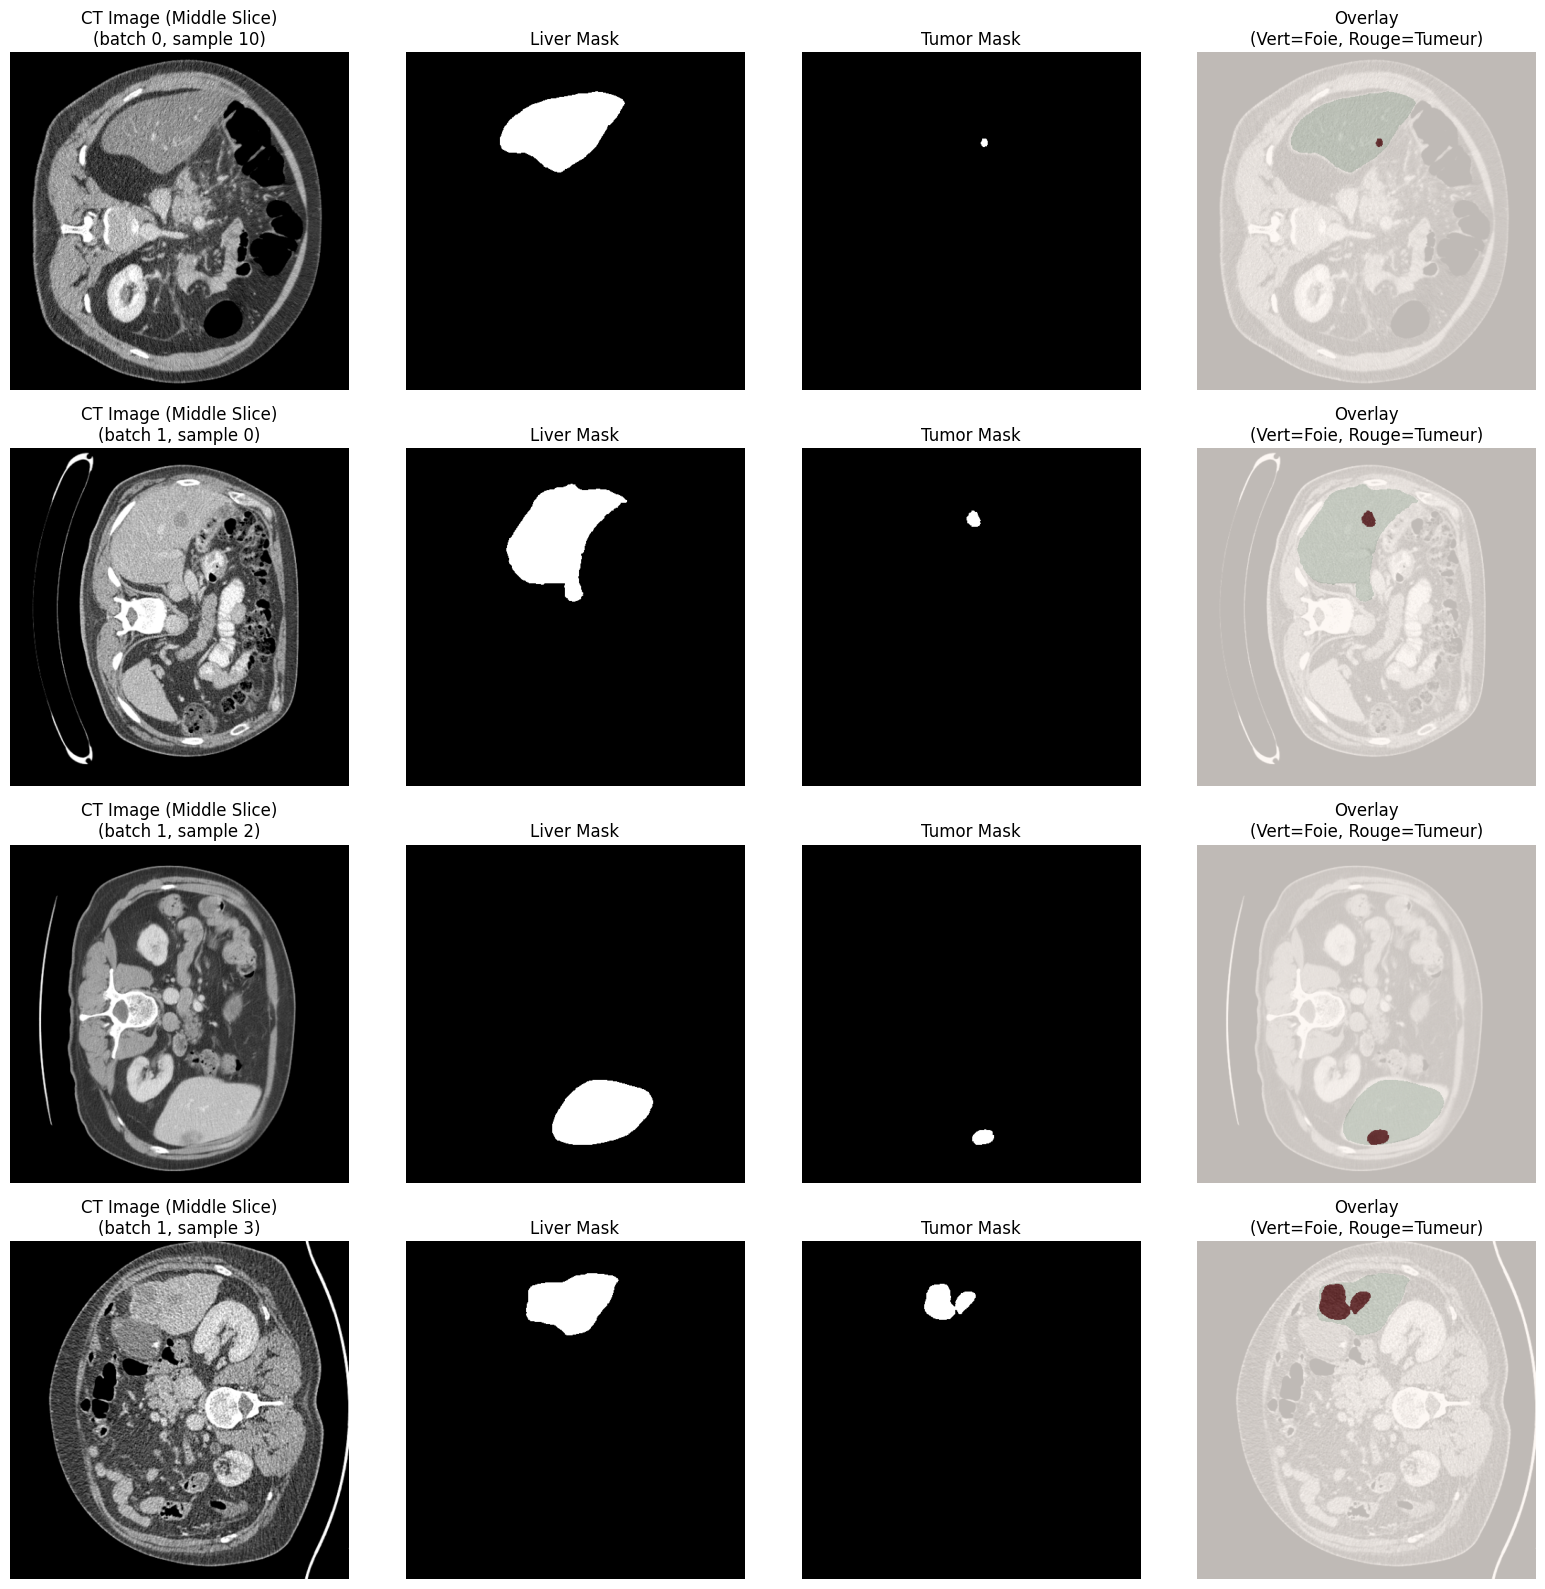

4 slices avec foie ET tumeur trouvees et affichees


In [7]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

import matplotlib.pyplot as plt
def visualize_dataloader_with_tumor(loader, max_samples=4):
    samples_with_tumor = []
    
    for batch_idx, batch in enumerate(loader):
        images = batch['image']
        targets = batch['target']  # (B, 480, 480) valeurs 0/1/2
        
        for i in range(images.shape[0]):
            target = targets[i].numpy()  # (480, 480)
            liver_mask = (target >= 1).astype(np.float32)
            tumor_mask = (target == 2).astype(np.float32)
            
            has_liver = liver_mask.sum() > 0
            has_tumor = tumor_mask.sum() > 0
            
            if has_liver and has_tumor:
                image_25d   = images[i].numpy()   # (3, 480, 480)
                image_middle = image_25d[1, :, :]  # slice du milieu
                
                samples_with_tumor.append({
                    'image':      image_middle,
                    'liver_mask': liver_mask,
                    'tumor_mask': tumor_mask,
                    'batch_idx':  batch_idx,
                    'sample_idx': i
                })
                
                if len(samples_with_tumor) >= max_samples:
                    break
        
        if len(samples_with_tumor) >= max_samples:
            break
    
    if not samples_with_tumor:
        print("Aucune slice avec foie ET tumeur trouvee!")
        return
    
    num_samples = len(samples_with_tumor)
    fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))
    if num_samples == 1:
        axes = axes[None, :]
    
    for idx, sample in enumerate(samples_with_tumor):
        img_np   = sample['image']
        liver_np = sample['liver_mask']
        tumor_np = sample['tumor_mask']
        
        axes[idx, 0].imshow(img_np, cmap='gray')
        axes[idx, 0].set_title(f"CT Image (Middle Slice)\n(batch {sample['batch_idx']}, sample {sample['sample_idx']})")
        axes[idx, 0].axis('off')
        
        axes[idx, 1].imshow(liver_np, cmap='gray')
        axes[idx, 1].set_title("Liver Mask")
        axes[idx, 1].axis('off')
        
        axes[idx, 2].imshow(tumor_np, cmap='gray')
        axes[idx, 2].set_title("Tumor Mask")
        axes[idx, 2].axis('off')
        
        axes[idx, 3].imshow(img_np, cmap='gray')
        axes[idx, 3].imshow(liver_np, cmap='Greens', alpha=0.4)
        axes[idx, 3].imshow(tumor_np, cmap='Reds',   alpha=0.6)
        axes[idx, 3].set_title("Overlay\n(Vert=Foie, Rouge=Tumeur)")
        axes[idx, 3].axis('off')
    
    plt.tight_layout()
    plt.show()
    print(f"{num_samples} slices avec foie ET tumeur trouvees et affichees")

visualize_dataloader_with_tumor(train_loader_fast, max_samples=4)

# SECTION 8: OPTIMISATION HYPERPARAMÈTRES
Tuning avec Optuna (TPE + Median Pruning) - explore LR, batch_size, poids loss, seuils

In [12]:
# # ===== CELL HT: HYPERPARAMETER TUNING AVEC OPTUNA =====
# # ⚠️  À EXÉCUTER AVANT LE TRAINING (Cell 7)
# # Les meilleurs hyperparamètres seront appliqués automatiquement au training.

# import subprocess, sys
# try:
#     import optuna
# except ImportError:
#     subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
#     import optuna

# import optuna
# from optuna.pruners import MedianPruner
# from optuna.samplers import TPESampler
# import torch, numpy as np, gc
# optuna.logging.set_verbosity(optuna.logging.WARNING)

# print("="*70)
# print("🔍 HYPERPARAMETER TUNING - OPTUNA (TPE + Median Pruning)")
# print("="*70)
# print("""
# Hyperparamètres explorés:
#   - learning_rate   : [1e-5 .. 5e-3]  (log-uniform)
#   - weight_ce       : [0.2 .. 0.8]    (poids CrossEntropy dans CEDiceLoss)
#   - batch_size      : {4, 8, 12, 16}
#   - liver_threshold : [0.3 .. 0.7]    (seuil inference foie)
#   - tumor_threshold : [0.1 .. 0.5]    (seuil inference tumeur)
#   - optimizer_name  : {Adam, AdamW, SGD+momentum}

# Objectif: maximiser (Dice_foie + 2 * Dice_tumeur) / 3
#   → La tumeur est pondérée 2× car plus difficile et cliniquement critique
# """)

# # ─── CONFIG TUNING ────────────────────────────────────────────────────────────
# N_TRIALS       = 20    # Nombre d'essais Optuna (augmenter si plus de temps GPU)
# N_EPOCHS_TRIAL = 3     # Epochs par essai (rapide - pour comparer les configs)
# SUBSET_FRAC    = 0.3   # Fraction du train set utilisée par essai (accélère x3)
# HT_DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# # ──────────────────────────────────────────────────────────────────────────────

# def build_optimizer(trial, model_params):
#     name = trial.suggest_categorical("optimizer_name", ["Adam", "AdamW", "SGD"])
#     lr   = trial.suggest_float("learning_rate", 1e-5, 5e-3, log=True)
#     if name == "Adam":
#         return torch.optim.Adam(model_params, lr=lr)
#     elif name == "AdamW":
#         wd = trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True)
#         return torch.optim.AdamW(model_params, lr=lr, weight_decay=wd)
#     else:
#         mom = trial.suggest_float("momentum", 0.7, 0.99)
#         return torch.optim.SGD(model_params, lr=lr, momentum=mom, nesterov=True)


# def objective(trial):
#     weight_ce       = trial.suggest_float("weight_ce", 0.2, 0.8)
#     weight_dice     = 1.0 - weight_ce
#     batch_size      = trial.suggest_categorical("batch_size", [4, 8, 12, 16])
#     liver_threshold = trial.suggest_float("liver_threshold", 0.3, 0.7)
#     tumor_threshold = trial.suggest_float("tumor_threshold", 0.1, 0.5)

#     model_ht     = UNet(n_channels=3, n_classes=3).to(HT_DEVICE)
#     criterion_ht = CEDiceLoss(weight_ce=weight_ce, weight_dice=weight_dice)
#     optimizer_ht = build_optimizer(trial, model_ht.parameters())
#     scaler_ht    = torch.amp.GradScaler("cuda", enabled=(HT_DEVICE.type == "cuda"))

#     n_sub = max(1, int(len(train_dataset) * SUBSET_FRAC))
#     sub_indices = torch.randperm(len(train_dataset))[:n_sub].tolist()
#     sub_dataset = torch.utils.data.Subset(train_dataset, sub_indices)
#     ht_train_loader = torch.utils.data.DataLoader(
#         sub_dataset, batch_size=batch_size, shuffle=True,
#         num_workers=0, pin_memory=True
#     )

#     for epoch in range(N_EPOCHS_TRIAL):
#         model_ht.train()
#         for batch in ht_train_loader:
#             images = batch["image"].to(HT_DEVICE, non_blocking=True)
#             target = batch["target"].to(HT_DEVICE, non_blocking=True)
#             optimizer_ht.zero_grad()
#             with torch.amp.autocast("cuda", enabled=(HT_DEVICE.type == "cuda")):
#                 outputs = model_ht(images)
#                 loss    = criterion_ht(outputs, target)
#             scaler_ht.scale(loss).backward()
#             scaler_ht.step(optimizer_ht)
#             scaler_ht.update()

#         model_ht.eval()
#         dice_liver_list, dice_tumor_list = [], []
#         with torch.no_grad():
#             for batch in val_loader_fast:
#                 images = batch["image"].to(HT_DEVICE, non_blocking=True)
#                 target = batch["target"].to(HT_DEVICE, non_blocking=True)
#                 with torch.amp.autocast("cuda", enabled=(HT_DEVICE.type == "cuda")):
#                     outputs = model_ht(images)
#                 probs      = torch.softmax(outputs, dim=1)
#                 liver_pred = (probs[:, 1] > liver_threshold).float()
#                 tumor_pred = (probs[:, 2] > tumor_threshold).float() * liver_pred
#                 liver_gt   = (target == 1).float()
#                 tumor_gt   = (target == 2).float()
#                 def batch_dice(p, g):
#                     inter = (p * g).sum(dim=(1,2))
#                     union = p.sum(dim=(1,2)) + g.sum(dim=(1,2))
#                     return ((2*inter + 1e-6) / (union + 1e-6)).mean().item()
#                 dice_liver_list.append(batch_dice(liver_pred, liver_gt))
#                 dice_tumor_list.append(batch_dice(tumor_pred, tumor_gt))

#         dice_l = float(np.mean(dice_liver_list))
#         dice_t = float(np.mean(dice_tumor_list))
#         score  = (dice_l + 2.0 * dice_t) / 3.0

#         trial.report(score, epoch)
#         if trial.should_prune():
#             del model_ht; gc.collect(); torch.cuda.empty_cache()
#             raise optuna.exceptions.TrialPruned()

#     del model_ht; gc.collect(); torch.cuda.empty_cache()
#     return score


# # ── Lancer l'étude ──────────────────────────────────────────────────────────
# study = optuna.create_study(
#     direction  = "maximize",
#     sampler    = TPESampler(seed=42),
#     pruner     = MedianPruner(n_startup_trials=5, n_warmup_steps=1),
#     study_name = "unet_lits_tuning"
# )
# print(f"🚀 Démarrage de {N_TRIALS} trials ({N_EPOCHS_TRIAL} epochs chacun)...\n")
# study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

# # ── Résultats ────────────────────────────────────────────────────────────────
# best = study.best_trial
# print("\n" + "="*70)
# print("✅ MEILLEURS HYPERPARAMÈTRES TROUVÉS")
# print("="*70)
# print(f"  Score combiné (Dice foie + 2×Dice tumeur)/3 : {best.value:.4f}")
# print("\n  Paramètres optimaux:")
# for k, v in best.params.items():
#     print(f"    {k:<22} = {v}")

# # ── Visualisation ────────────────────────────────────────────────────────────
# import matplotlib.pyplot as plt

# fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# values = [t.value for t in study.trials if t.value is not None]
# axes[0].plot(range(len(values)), values, "o-", color="steelblue", linewidth=2, markersize=6)
# axes[0].axhline(max(values), color="red", linestyle="--", label=f"Best: {max(values):.4f}")
# axes[0].set_title("Score par trial", fontsize=13, fontweight="bold")
# axes[0].set_xlabel("Trial"); axes[0].set_ylabel("Score combiné Dice")
# axes[0].legend(); axes[0].grid(True, alpha=0.4)

# try:
#     importances = optuna.importance.get_param_importances(study)
#     axes[1].barh(list(importances.keys()), list(importances.values()), color="tomato")
#     axes[1].set_title("Importance des hyperparamètres", fontsize=13, fontweight="bold")
#     axes[1].set_xlabel("Importance relative"); axes[1].grid(True, axis="x", alpha=0.4)
# except Exception:
#     axes[1].text(0.5, 0.5, "Importance\nnon disponible", ha="center", va="center", transform=axes[1].transAxes)

# lrs    = [t.params.get("learning_rate") for t in study.trials if t.value is not None]
# scores = [t.value for t in study.trials if t.value is not None]
# sc = axes[2].scatter(lrs, scores, c=scores, cmap="viridis", s=80, zorder=5)
# axes[2].set_xscale("log")
# axes[2].set_title("Learning Rate vs Score", fontsize=13, fontweight="bold")
# axes[2].set_xlabel("Learning Rate (log)"); axes[2].set_ylabel("Score combiné Dice")
# plt.colorbar(sc, ax=axes[2], label="Score"); axes[2].grid(True, alpha=0.4)

# plt.suptitle("Résultats Hyperparameter Tuning - UNet LiTS", fontsize=15, fontweight="bold")
# plt.tight_layout()
# plt.savefig("/kaggle/working/hyperparameter_tuning.png", dpi=150, bbox_inches="tight")
# plt.show()

# # ── Injecter automatiquement les meilleurs hyperparamètres pour le training ──
# p = best.params
# BEST_LR             = p["learning_rate"]
# BEST_WEIGHT_CE      = p["weight_ce"]
# BEST_WEIGHT_DICE    = 1.0 - p["weight_ce"]
# BEST_BATCH_SIZE     = p["batch_size"]
# BEST_OPTIMIZER_NAME = p["optimizer_name"]
# BEST_LIVER_THRESH   = p["liver_threshold"]
# BEST_TUMOR_THRESH   = p["tumor_threshold"]

# print("\n" + "="*70)
# print("🔧 HYPERPARAMÈTRES INJECTÉS — prêts pour Cell 7 (Training)")
# print("="*70)
# print(f"  BEST_LR             = {BEST_LR:.2e}")
# print(f"  BEST_WEIGHT_CE      = {BEST_WEIGHT_CE:.3f}")
# print(f"  BEST_WEIGHT_DICE    = {BEST_WEIGHT_DICE:.3f}")
# print(f"  BEST_BATCH_SIZE     = {BEST_BATCH_SIZE}")
# print(f"  BEST_OPTIMIZER_NAME = {BEST_OPTIMIZER_NAME}")
# print(f"  BEST_LIVER_THRESH   = {BEST_LIVER_THRESH:.3f}")
# print(f"  BEST_TUMOR_THRESH   = {BEST_TUMOR_THRESH:.3f}")
# print("\n✅ Exécutez maintenant Cell 7 (Training) → elle lira ces variables.")

# import json
# with open("/kaggle/working/best_hyperparams.json", "w") as f:
#     json.dump({"score": best.value, "params": p}, f, indent=2)
# print("💾 Sauvegardé: /kaggle/working/best_hyperparams.json")


In [ ]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

import subprocess, sys, json, os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"  # ← ADD

try:
    import optuna
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna

import optuna
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler
import torch, numpy as np, gc
from tqdm import tqdm
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("="*70)
print("🔍 HYPERPARAMETER TUNING - OPTUNA (TPE + Median Pruning)")
print("="*70)

N_TRIALS        = 20
N_EPOCHS_TRIAL  = 2
SUBSET_FRAC     = 0.3
HT_DEVICE       = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BEST_HP_PATH    = "/workspace/best_hyperparams.json"

completed_trials = 0
if os.path.exists(BEST_HP_PATH):
    with open(BEST_HP_PATH, "r") as f:
        saved = json.load(f)
    print(f"💾 Checkpoint trouvé: best score précédent = {saved['score']:.4f}")
    print(f"   Paramètres sauvegardés: {saved['params']}")
    print(f"   → Le tuning va continuer et écraser si un meilleur score est trouvé.\n")
else:
    print("Aucun checkpoint trouvé → tuning from scratch.\n")


def build_optimizer(trial, model_params):
    name = trial.suggest_categorical("optimizer_name", ["Adam", "AdamW", "SGD"])
    lr   = trial.suggest_float("learning_rate", 1e-5, 5e-3, log=True)
    if name == "Adam":
        return torch.optim.Adam(model_params, lr=lr)
    elif name == "AdamW":
        wd = trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True)
        return torch.optim.AdamW(model_params, lr=lr, weight_decay=wd)
    else:
        mom = trial.suggest_float("momentum", 0.7, 0.99)
        return torch.optim.SGD(model_params, lr=lr, momentum=mom, nesterov=True)


def objective(trial):
    weight_ce       = trial.suggest_float("weight_ce", 0.2, 0.8)
    weight_dice     = 1.0 - weight_ce
    batch_size      = trial.suggest_categorical("batch_size", [4, 8, 12])  # ← REMOVED 16
    liver_threshold = trial.suggest_float("liver_threshold", 0.3, 0.7)
    tumor_threshold = trial.suggest_float("tumor_threshold", 0.1, 0.5)

    print(f"\n{'─'*70}")
    print(f"🔬 Trial {trial.number+1}/{N_TRIALS}")
    print(f"   optimizer  = {trial.params.get('optimizer_name', '...')}")
    print(f"   lr         = {trial.params.get('learning_rate', '...'):.2e}" if 'learning_rate' in trial.params else "   lr         = ...")
    print(f"   batch_size = {batch_size}")
    print(f"   weight_ce  = {weight_ce:.3f}  |  weight_dice = {weight_dice:.3f}")
    print(f"   liver_thr  = {liver_threshold:.3f}  |  tumor_thr   = {tumor_threshold:.3f}")
    print(f"{'─'*70}")

    model_ht     = UNet(n_channels=3, n_classes=3).to(HT_DEVICE)
    criterion_ht = CEDiceLoss(weight_ce=weight_ce, weight_dice=weight_dice)
    optimizer_ht = build_optimizer(trial, model_ht.parameters())
    scaler_ht    = torch.amp.GradScaler("cuda", enabled=(HT_DEVICE.type == "cuda"))

    n_sub = max(1, int(len(train_dataset) * SUBSET_FRAC))
    sub_indices = torch.randperm(len(train_dataset))[:n_sub].tolist()
    sub_dataset = torch.utils.data.Subset(train_dataset, sub_indices)
    ht_train_loader = torch.utils.data.DataLoader(
        sub_dataset, batch_size=batch_size, shuffle=True,
        num_workers=2, pin_memory=True
    )

    best_epoch_score = 0.0

    for epoch in range(N_EPOCHS_TRIAL):

        # ── Training ────────────────────────────────────────────────────────
        model_ht.train()
        train_loss = 0.0
        pbar_train = tqdm(
            ht_train_loader,
            desc=f"  Epoch {epoch+1}/{N_EPOCHS_TRIAL} [Train]",
            unit="batch",
            leave=False
        )
        try:  # ← ADD try/except for OOM
            for batch in pbar_train:
                images = batch["image"].to(HT_DEVICE, non_blocking=True)
                target = batch["target"].to(HT_DEVICE, non_blocking=True)
                optimizer_ht.zero_grad()
                with torch.amp.autocast("cuda", enabled=(HT_DEVICE.type == "cuda")):
                    outputs = model_ht(images)
                    loss    = criterion_ht(outputs, target)
                scaler_ht.scale(loss).backward()
                scaler_ht.step(optimizer_ht)
                scaler_ht.update()
                train_loss += loss.item()
                pbar_train.set_postfix({"loss": f"{loss.item():.4f}"})
        except torch.cuda.OutOfMemoryError:  # ← ADD
            print(f"  💥 OOM à epoch {epoch+1}, trial pruné.")
            del model_ht; gc.collect(); torch.cuda.empty_cache()
            raise optuna.exceptions.TrialPruned()

        avg_train_loss = train_loss / len(ht_train_loader)

        # ── Validation ──────────────────────────────────────────────────────
        model_ht.eval()
        dice_liver_list, dice_tumor_list = [], []
        pbar_val = tqdm(
            val_loader_fast,
            desc=f"  Epoch {epoch+1}/{N_EPOCHS_TRIAL} [Val]  ",
            unit="batch",
            leave=False
        )
        with torch.no_grad():
            for batch in pbar_val:
                images = batch["image"].to(HT_DEVICE, non_blocking=True)
                target = batch["target"].to(HT_DEVICE, non_blocking=True)
                with torch.amp.autocast("cuda", enabled=(HT_DEVICE.type == "cuda")):
                    outputs = model_ht(images)
                probs      = torch.softmax(outputs, dim=1)
                liver_pred = (probs[:, 1] > liver_threshold).float()
                tumor_pred = (probs[:, 2] > tumor_threshold).float() * liver_pred
                liver_gt   = (target == 1).float()
                tumor_gt   = (target == 2).float()
                def batch_dice(p, g):
                    inter = (p * g).sum(dim=(1,2))
                    union = p.sum(dim=(1,2)) + g.sum(dim=(1,2))
                    return ((2*inter + 1e-6) / (union + 1e-6)).mean().item()
                dice_liver_list.append(batch_dice(liver_pred, liver_gt))
                dice_tumor_list.append(batch_dice(tumor_pred, tumor_gt))
                pbar_val.set_postfix({
                    "dice_foie":   f"{np.mean(dice_liver_list):.4f}",
                    "dice_tumeur": f"{np.mean(dice_tumor_list):.4f}"
                })

        dice_l = float(np.mean(dice_liver_list))
        dice_t = float(np.mean(dice_tumor_list))
        score  = -( (dice_l + dice_t) / 2 )

        print(f"  📊 Epoch {epoch+1}/{N_EPOCHS_TRIAL} | "
              f"train_loss={avg_train_loss:.4f} | "
              f"dice_foie={dice_l:.4f} | "
              f"dice_tumeur={dice_t:.4f} | "
              f"score={-score:.4f}")

        best_epoch_score = max(best_epoch_score, -score)

        trial.report(-score, epoch)
        if trial.should_prune():
            print(f"  ✂️  Trial {trial.number+1} prunté à epoch {epoch+1} "
                  f"(score {-score:.4f} < médiane)")
            del model_ht; gc.collect(); torch.cuda.empty_cache()
            raise optuna.exceptions.TrialPruned()

    del model_ht; gc.collect(); torch.cuda.empty_cache()
    print(f"  ✅ Trial {trial.number+1} terminé | meilleur score = {best_epoch_score:.4f}")
    return -score


study = optuna.create_study(
    direction  = "minimize",
    sampler    = TPESampler(seed=42),
    pruner     = MedianPruner(n_startup_trials=5, n_warmup_steps=1),
    study_name = "unet_lits_tuning"
)

print(f"🚀 Démarrage de {N_TRIALS} trials ({N_EPOCHS_TRIAL} epochs chacun)...\n")
study.optimize(objective, n_trials=N_TRIALS, catch=(torch.cuda.OutOfMemoryError,))  # ← ADD catch

best = study.best_trial
print("\n" + "="*70)
print("✅ MEILLEURS HYPERPARAMÈTRES TROUVÉS")
print("="*70)
print(f"  Score (Dice moyen foie+tumeur) : {-best.value:.4f}")
print("\n  Paramètres optimaux:")
for k, v in best.params.items():
    print(f"    {k:<22} = {v}")

os.makedirs(os.path.dirname(BEST_HP_PATH), exist_ok=True)
best_data = {"score": -best.value, "params": best.params}
with open(BEST_HP_PATH, "w") as f:
    json.dump(best_data, f, indent=2)
print(f"\n💾 Checkpoint sauvegardé → {BEST_HP_PATH}")

p = best.params
BEST_LR             = p["learning_rate"]
BEST_WEIGHT_CE      = p["weight_ce"]
BEST_WEIGHT_DICE    = 1.0 - p["weight_ce"]
BEST_BATCH_SIZE     = p["batch_size"]
BEST_OPTIMIZER_NAME = p["optimizer_name"]
BEST_LIVER_THRESH   = p["liver_threshold"]
BEST_TUMOR_THRESH   = p["tumor_threshold"]

print("\n" + "="*70)
print("🔧 VARIABLES INJECTÉES — prêtes pour le Training (Cell suivante)")
print("="*70)
print(f"  BEST_LR             = {BEST_LR:.2e}")
print(f"  BEST_WEIGHT_CE      = {BEST_WEIGHT_CE:.3f}")
print(f"  BEST_WEIGHT_DICE    = {BEST_WEIGHT_DICE:.3f}")
print(f"  BEST_BATCH_SIZE     = {BEST_BATCH_SIZE}")
print(f"  BEST_OPTIMIZER_NAME = {BEST_OPTIMIZER_NAME}")
print(f"  BEST_LIVER_THRESH   = {BEST_LIVER_THRESH:.3f}")
print(f"  BEST_TUMOR_THRESH   = {BEST_TUMOR_THRESH:.3f}")
print("\n✅ Exécutez maintenant la cellule Training.")

START: 16:55:13
🔍 HYPERPARAMETER TUNING - OPTUNA (TPE + Median Pruning)
Aucun checkpoint trouvé → tuning from scratch.

🚀 Démarrage de 20 trials (2 epochs chacun)...


──────────────────────────────────────────────────────────────────────
🔬 Trial 1/20
   optimizer  = ...
   lr         = ...
   batch_size = 4
   weight_ce  = 0.425  |  weight_dice = 0.575
   liver_thr  = 0.362  |  tumor_thr   = 0.162
──────────────────────────────────────────────────────────────────────


  📊 Epoch 1/2 | train_loss=0.2721 | dice_foie=0.7549 | dice_tumeur=0.7877 | score=0.7713


  📊 Epoch 2/2 | train_loss=0.1755 | dice_foie=0.8527 | dice_tumeur=0.7877 | score=0.8202
  ✅ Trial 1 terminé | meilleur score = 0.8202

──────────────────────────────────────────────────────────────────────
🔬 Trial 2/20
   optimizer  = ...
   lr         = ...
   batch_size = 4
   weight_ce  = 0.782  |  weight_dice = 0.218
   liver_thr  = 0.373  |  tumor_thr   = 0.222
──────────────────────────────────────────────────────────────────────


  📊 Epoch 1/2 | train_loss=0.1733 | dice_foie=0.7881 | dice_tumeur=0.7345 | score=0.7613


  📊 Epoch 2/2 | train_loss=0.1128 | dice_foie=0.8075 | dice_tumeur=0.6133 | score=0.7104
  ✅ Trial 2 terminé | meilleur score = 0.7613

──────────────────────────────────────────────────────────────────────
🔬 Trial 3/20
   optimizer  = ...
   lr         = ...
   batch_size = 12
   weight_ce  = 0.284  |  weight_dice = 0.716
   liver_thr  = 0.614  |  tumor_thr   = 0.180
──────────────────────────────────────────────────────────────────────


...

  📊 Epoch 2/2 | train_loss=0.2532 | dice_foie=0.8531 | dice_tumeur=0.7877 | score=0.8204
  ✂️  Trial 18 prunté à epoch 2 (score 0.8204 < médiane)

──────────────────────────────────────────────────────────────────────
🔬 Trial 19/20
   optimizer  = ...
   lr         = ...
   batch_size = 8
   weight_ce  = 0.724  |  weight_dice = 0.276
   liver_thr  = 0.302  |  tumor_thr   = 0.173
──────────────────────────────────────────────────────────────────────


  📊 Epoch 1/2 | train_loss=0.1739 | dice_foie=0.6191 | dice_tumeur=0.6948 | score=0.6570


  📊 Epoch 2/2 | train_loss=0.1123 | dice_foie=0.7471 | dice_tumeur=0.6546 | score=0.7009
  ✅ Trial 19 terminé | meilleur score = 0.7009

──────────────────────────────────────────────────────────────────────
🔬 Trial 20/20
   optimizer  = ...
   lr         = ...
   batch_size = 12
   weight_ce  = 0.560  |  weight_dice = 0.440
   liver_thr  = 0.612  |  tumor_thr   = 0.441
──────────────────────────────────────────────────────────────────────


  📊 Epoch 1/2 | train_loss=0.2209 | dice_foie=0.6693 | dice_tumeur=0.7877 | score=0.7285


  📊 Epoch 2/2 | train_loss=0.1653 | dice_foie=0.7845 | dice_tumeur=0.7877 | score=0.7861
  ✂️  Trial 20 prunté à epoch 2 (score 0.7861 < médiane)

✅ MEILLEURS HYPERPARAMÈTRES TROUVÉS
  Score (Dice moyen foie+tumeur) : -0.6619

  Paramètres optimaux:
    weight_ce              = 0.2836963163912251
    batch_size             = 12
    liver_threshold        = 0.6140703845572054
    tumor_threshold        = 0.1798695128633439
    optimizer_name         = AdamW
    learning_rate          = 0.00043625993625605574
    weight_decay           = 3.247673570627447e-05

💾 Checkpoint sauvegardé → /workspace/best_hyperparams.json

🔧 VARIABLES INJECTÉES — prêtes pour le Training (Cell suivante)
  BEST_LR             = 4.36e-04
  BEST_WEIGHT_CE      = 0.284
  BEST_WEIGHT_DICE    = 0.716
  BEST_BATCH_SIZE     = 12
  BEST_OPTIMIZER_NAME = AdamW
  BEST_LIVER_THRESH   = 0.614
  BEST_TUMOR_THRESH   = 0.180

✅ Exécutez maintenant la cellule Training.


# SECTION 9: ENTRAÎNEMENT DU MODÈLE  
Boucle d'entraînement avec AMP (Automatic Mixed Precision), checkpoints, et suivi des métriques (10 epochs)

In [10]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# ===== CELL 7: TRAINING LOOP (AMP + history complet) =====
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"  # ← ADD

os.makedirs("/workspace/checkpoints", exist_ok=True)
CHECKPOINT_PATH = "/workspace/checkpoints/checkpoint.pth"
BEST_MODEL_PATH = "/workspace/checkpoints/best_model.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

try:
    lr         = BEST_LR
    weight_ce  = BEST_WEIGHT_CE
    weight_dice= BEST_WEIGHT_DICE
    BATCH_SIZE = BEST_BATCH_SIZE
    opt_name   = BEST_OPTIMIZER_NAME
    print(f"✅ Hyperparamètres Optuna chargés: lr={lr:.2e}, batch={BATCH_SIZE}, optim={opt_name}")
except NameError:
    lr         = 1e-4
    weight_ce  = 0.5
    weight_dice= 0.5
    BATCH_SIZE = 8  # ← CHANGED from 12 to 8 (safer default for 16GB)
    opt_name   = "Adam"
    print("⚠️  Tuning non exécuté → hyperparamètres par défaut utilisés.")

train_loader_fast = torch.utils.data.DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True  # ← CHANGED num_workers 0→2
)
val_loader_fast = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)
test_loader_fast = torch.utils.data.DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)

model     = UNet(n_channels=3, n_classes=3).to(device)
criterion = CEDiceLoss(weight_ce=weight_ce, weight_dice=weight_dice)

if opt_name == "AdamW":
    wd = best.params.get("weight_decay", 1e-4) if "best" in dir() else 1e-4
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
elif opt_name == "SGD":
    mom = best.params.get("momentum", 0.9) if "best" in dir() else 0.9
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=mom, nesterov=True)
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

use_amp = device.type == "cuda"
scaler  = torch.amp.GradScaler("cuda", enabled=use_amp)

num_epochs    = 10
start_epoch   = 0
best_val_loss = float("inf")

history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  [],
    "train_dice_liver": [], "val_dice_liver": [],
    "train_dice_tumor": [], "val_dice_tumor": [],
}

def compute_acc(outputs, target):
    return (torch.argmax(outputs, dim=1) == target).float().mean().item()

def compute_dice(outputs, target, cls):
    pred  = (torch.argmax(outputs, dim=1) == cls).float()
    gt    = (target == cls).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum()
    return (2 * inter / (union + 1e-6)).item()

if os.path.exists(CHECKPOINT_PATH):
    print("Checkpoint trouvé, reprise...")
    ckpt = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if "scaler_state_dict" in ckpt:
        scaler.load_state_dict(ckpt["scaler_state_dict"])
    start_epoch   = ckpt.get("epoch", 0) + 1
    best_val_loss = ckpt.get("best_val_loss", float("inf"))
    if "history" in ckpt:
        history = ckpt["history"]
    print(f"Reprise à epoch {start_epoch}")

for epoch in range(start_epoch, num_epochs):
    model.train()
    train_loss, train_acc_list = 0.0, []
    train_dice_liver_list, train_dice_tumor_list = [], []
    pbar = tqdm(enumerate(train_loader_fast), total=len(train_loader_fast),
                desc=f"Epoch {epoch+1:2d}/{num_epochs}", unit="batch", leave=True)

    try:  # ← ADD try/except for OOM
        for batch_idx, batch in pbar:
            images = batch["image"].to(device, non_blocking=True)
            target = batch["target"].to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.amp.autocast("cuda", enabled=use_amp):
                outputs = model(images)
                loss    = criterion(outputs, target)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item()
            with torch.no_grad():
                train_acc_list.append(compute_acc(outputs, target))
                train_dice_liver_list.append(compute_dice(outputs, target, cls=1))
                train_dice_tumor_list.append(compute_dice(outputs, target, cls=2))
            pbar.set_postfix({"loss": f"{train_loss/(batch_idx+1):.4f}"}, refresh=True)
    except torch.cuda.OutOfMemoryError:  # ← ADD
        print(f"  💥 OOM à epoch {epoch+1}, nettoyage mémoire et skip.")
        gc.collect()
        torch.cuda.empty_cache()
        continue  # skip to next epoch instead of crashing

    avg_train_loss       = train_loss / len(train_loader_fast)
    avg_train_acc        = np.mean(train_acc_list)
    avg_train_dice_liver = np.mean(train_dice_liver_list)
    avg_train_dice_tumor = np.mean(train_dice_tumor_list)

    model.eval()
    val_loss, val_acc_list = 0.0, []
    val_dice_liver_list, val_dice_tumor_list = [], []
    with torch.no_grad():
        for batch in val_loader_fast:
            images = batch["image"].to(device, non_blocking=True)
            target = batch["target"].to(device, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                outputs = model(images)
                loss    = criterion(outputs, target)
            val_loss += loss.item()
            val_acc_list.append(compute_acc(outputs, target))
            val_dice_liver_list.append(compute_dice(outputs, target, cls=1))
            val_dice_tumor_list.append(compute_dice(outputs, target, cls=2))

    avg_val_loss       = val_loss / len(val_loader_fast)
    avg_val_acc        = np.mean(val_acc_list)
    avg_val_dice_liver = np.mean(val_dice_liver_list)
    avg_val_dice_tumor = np.mean(val_dice_tumor_list)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["train_acc"].append(avg_train_acc)
    history["val_acc"].append(avg_val_acc)
    history["train_dice_liver"].append(avg_train_dice_liver)
    history["val_dice_liver"].append(avg_val_dice_liver)
    history["train_dice_tumor"].append(avg_train_dice_tumor)
    history["val_dice_tumor"].append(avg_val_dice_tumor)

    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f} Acc: {avg_train_acc:.4f} | Val Loss: {avg_val_loss:.4f} Acc: {avg_val_acc:.4f}")

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "history": history,
    }, CHECKPOINT_PATH)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"Meilleur modèle sauvegardé (val_loss: {avg_val_loss:.4f})")

    gc.collect()               # ← ADD: clean up each epoch
    torch.cuda.empty_cache()   # ← ADD

print("Entraînement terminé!")

START: 22:50:27
Device: cuda
GPU: NVIDIA RTX A4000
VRAM: 16.9 GB
✅ Hyperparamètres Optuna chargés: lr=4.36e-04, batch=12, optim=AdamW


Epoch  1/10: 100%|██████████| 1979/1979 [22:13<00:00,  1.48batch/s, loss=0.2636]


Epoch 1/10 | Train Loss: 0.2636 Acc: 0.9873 | Val Loss: 0.3669 Acc: 0.9942
Meilleur modèle sauvegardé (val_loss: 0.3669)


Epoch  2/10: 100%|██████████| 1979/1979 [22:15<00:00,  1.48batch/s, loss=0.1700]


Epoch 2/10 | Train Loss: 0.1700 Acc: 0.9935 | Val Loss: 0.2120 Acc: 0.9957
Meilleur modèle sauvegardé (val_loss: 0.2120)


...

Epoch 8/10 | Train Loss: 0.1240 Acc: 0.9961 | Val Loss: 0.2095 Acc: 0.9956


Epoch  9/10: 100%|██████████| 1979/1979 [22:08<00:00,  1.49batch/s, loss=0.1267]


Epoch 9/10 | Train Loss: 0.1267 Acc: 0.9958 | Val Loss: 0.1955 Acc: 0.9963
Meilleur modèle sauvegardé (val_loss: 0.1955)


Epoch 10/10: 100%|██████████| 1979/1979 [22:01<00:00,  1.50batch/s, loss=0.2143]


Epoch 10/10 | Train Loss: 0.2143 Acc: 0.9946 | Val Loss: 0.2030 Acc: 0.9956
Entraînement terminé!


#  SECTION 10: PIPELINE D'INFÉRENCE
Pipeline multiclass avec seuils adaptéset contrainte anatomique

In [10]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# ===== CELL 8: INFERENCE PIPELINE MULTICLASS =====
print("="*70)
print("🎯 INFERENCE PIPELINE MULTICLASS (SINGLE MODEL)")
print("="*70)

def compute_metrics_full(pred, target, smooth=1.0):
    """Calcule Dice, IoU, Precision, Recall, F1"""
    pred = pred.float()
    target = target.float()
    
    tp = (pred * target).sum()
    fp = (pred * (1 - target)).sum()
    fn = ((1 - pred) * target).sum()
    
    dice = (2.0 * tp + smooth) / (2.0 * tp + fp + fn + smooth)
    iou = (tp + smooth) / (tp + fp + fn + smooth)
    precision = (tp + smooth) / (tp + fp + smooth)
    recall = (tp + smooth) / (tp + fn + smooth)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-8)
    
    return {
        'dice': dice.item(),
        'iou': iou.item(),
        'precision': precision.item(),
        'recall': recall.item(),
        'f1': f1.item()
    }


class MulticlassSegmentationPipeline:
    """
    Pipeline d'inférence Multiclass (UNet unique):
    1) Extraire les prédictions du modèle multiclass (3 classes)
    2) Classe 1 = Foie, Classe 2 = Tumeur
    3) Appliquer seuils différenciés par classe
    4) Appliquer constraint anatomique: tumor ⊂ liver
    """
    
    def __init__(self, model, device, margin=20, liver_threshold=0.5, tumor_threshold=0.3):
        self.model = model
        self.device = device
        self.margin = margin
        self.liver_threshold = liver_threshold
        self.tumor_threshold = tumor_threshold
    
    def forward(self, image_25d):
        """
        Args:
            image_25d: tensor (3, H, W) ou (B, 3, H, W)
        
        Returns:
            pred_liver: tensor binaire (H, W)
            pred_tumor: tensor binaire (H, W)
        """
        if image_25d.dim() == 3:
            image_25d = image_25d.unsqueeze(0)  # (1, 3, H, W)
        
        _, _, H, W = image_25d.shape
        
        self.model.eval()
        with torch.no_grad():
            outputs = self.model(image_25d)
            probs = torch.softmax(outputs, dim=1)
            
            # Extraire liver (classe 1) et tumor (classe 2)
            liver_probs = probs[:, 1, :, :]  # (B, H, W)
            tumor_probs = probs[:, 2, :, :]  # (B, H, W)
            
            pred_liver = (liver_probs > self.liver_threshold).float().squeeze(0)
            pred_tumor = (tumor_probs > self.tumor_threshold).float().squeeze(0)
        
        # Contrainte anatomique: tumor ⊆ liver
        pred_tumor = pred_tumor * pred_liver
        
        return pred_liver, pred_tumor


# Charger le meilleur modèle
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model = UNet(n_channels=3, n_classes=3).to(device)

if os.path.exists(BEST_MODEL_PATH):
    print(f"✅ Meilleur modèle trouvé: {BEST_MODEL_PATH}")
    best_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
else:
    print(f"⚠️  Modèle non trouvé. Utilisation du modèle courant.")

# Créer pipeline
pipeline = MulticlassSegmentationPipeline(best_model, device, liver_threshold=0.5, tumor_threshold=0.3)

print(f"\n✅ Pipeline Multiclass créé")
print(f"   Seuil foie: 0.50")
print(f"   Seuil tumeur: 0.30")
print("="*70 + "\n")

START: 15:29:47
🎯 INFERENCE PIPELINE MULTICLASS (SINGLE MODEL)
⚠️  Modèle non trouvé. Utilisation du modèle courant.

✅ Pipeline Multiclass créé
   Seuil foie: 0.50
   Seuil tumeur: 0.30



#  SECTION 11: PRÉDICTION SUR VOLUMES 3D
Fonction predict_on_volume - inférence batch sur volumes entiers avec optimization GPU

In [11]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

def predict_on_volume(volume_path, seg_path, pipeline, device):
    volume_data = nib.load(volume_path).get_fdata()
    seg_data    = nib.load(seg_path).get_fdata()
    H, W, D     = volume_data.shape

    volume_normalized = (np.clip(volume_data, -200, 200) + 200) / 400
    volume_normalized = volume_normalized.astype(np.float32)

    pred_liver_volume = np.zeros((H, W, D), dtype=np.uint8)
    pred_tumor_volume = np.zeros((H, W, D), dtype=np.uint8)

    # Preparer TOUTES les slices 2.5D du volume en une fois
    slices_25d = np.stack([
        np.stack([volume_normalized[:, :, z-1],
                  volume_normalized[:, :, z],
                  volume_normalized[:, :, z+1]], axis=0)
        for z in range(1, D-1)
    ], axis=0)  # (D-2, 3, H, W)

    # Inference en batch (pas slice par slice)
    INFER_BATCH = 16
    pipeline.model.eval()
    with torch.no_grad():
        for i in range(0, len(slices_25d), INFER_BATCH):
            batch = torch.from_numpy(slices_25d[i:i+INFER_BATCH]).float().to(device)
            with torch.amp.autocast("cuda", enabled=True):
                outputs = pipeline.model(batch)
                probs   = torch.softmax(outputs, dim=1)
            liver_pred = (probs[:, 1, :, :] > pipeline.liver_threshold).cpu().numpy().astype(np.uint8)
            tumor_pred = (probs[:, 2, :, :] > pipeline.tumor_threshold).cpu().numpy().astype(np.uint8)
            tumor_pred = tumor_pred * liver_pred  # contrainte anatomique

            for j in range(len(liver_pred)):
                z = i + j + 1
                pred_liver_volume[:, :, z] = liver_pred[j]
                pred_tumor_volume[:, :, z] = tumor_pred[j]

    liver_gt       = (seg_data >= 1).astype(np.uint8)
    tumor_gt       = (seg_data == 2).astype(np.uint8)
    dice_liver_vol = 2 * (pred_liver_volume * liver_gt).sum() / (pred_liver_volume.sum() + liver_gt.sum() + 1e-6)
    dice_tumor_vol = 2 * (pred_tumor_volume * tumor_gt).sum() / (pred_tumor_volume.sum() + tumor_gt.sum() + 1e-6)

    return {
        'volume': volume_data, 'volume_norm': volume_normalized, 'seg': seg_data,
        'pred_liver': pred_liver_volume, 'pred_tumor': pred_tumor_volume,
        'liver_gt': liver_gt, 'tumor_gt': tumor_gt,
        'dice_liver': dice_liver_vol, 'dice_tumor': dice_tumor_vol
    }

START: 15:29:48


#  SECTION 12: ÉVALUATION SUR TEST SET
Calcul des métriques (Dice, IoU, Precision, Recall, F1) par volume pour foie et tumeur

In [ ]:
# # ===== CELL 9: EVALUATION SUR TEST SET - DICE PAR VOLUME =====
# import gc
# print("="*70)
# print("EVALUATION SUR TEST SET - DICE PAR VOLUME")
# print("="*70)

# test_indices  = test_dataset.indices
# test_vol_ids  = list(set([dataset_full.slice_index[i][0] for i in test_indices]))
# print(f"Volumes dans test set: {len(test_vol_ids)}")

# dice_liver_list = []
# dice_tumor_list = []

# for vol_idx in tqdm(test_vol_ids, desc="Evaluation"):
#     row = df.iloc[vol_idx]
#     try:
#         result = predict_on_volume(
#             row['volume_path'],
#             row['segmentation_path'],
#             pipeline, device
#         )
#         dice_liver_list.append(result['dice_liver'])
#         dice_tumor_list.append(result['dice_tumor'])

#         # Liberer memoire apres chaque volume
#         del result
#         gc.collect()
#         torch.cuda.empty_cache()

#     except Exception as e:
#         tqdm.write(f"Erreur vol {vol_idx}: {e}")

# print(f"\nRESULTATS ({len(dice_liver_list)} volumes)")
# print("="*70)
# print(f"Dice Foie   | Moy: {np.mean(dice_liver_list):.4f} | Std: {np.std(dice_liver_list):.4f} | Min: {np.min(dice_liver_list):.4f} | Max: {np.max(dice_liver_list):.4f}")
# print(f"Dice Tumeur | Moy: {np.mean(dice_tumor_list):.4f} | Std: {np.std(dice_tumor_list):.4f} | Min: {np.min(dice_tumor_list):.4f} | Max: {np.max(dice_tumor_list):.4f}")

In [5]:
pip install datetime

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from datetime import datetime
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# ===== CELL 9: EVALUATION SUR TEST SET - METRIQUES PAR VOLUME =====
import gc

print("=" * 70)
print("TEST COMPLET: FOIE + TUMEUR (2-STAGE PIPELINE)")
print("=" * 70)

# FIX: test_df already contains only test volumes
test_vol_ids = list(test_df.index)

# Nombre de slices disponibles dans le test set (si construit), sinon fallback sur nb volumes
try:
    n_test_slices = len(test_dataset)
except Exception:
    n_test_slices = len(test_vol_ids)

def compute_volume_metrics(pred, gt):
    pred = pred.astype(np.float32)
    gt = gt.astype(np.float32)
    tp = (pred * gt).sum()
    fp = (pred * (1 - gt)).sum()
    fn = ((1 - pred) * gt).sum()
    smooth = 1e-6

    dice = (2 * tp + smooth) / (2 * tp + fp + fn + smooth)
    iou = (tp + smooth) / (tp + fp + fn + smooth)
    precision = (tp + smooth) / (tp + fp + smooth)
    recall = (tp + smooth) / (tp + fn + smooth)
    f1 = (2 * precision * recall) / (precision + recall + smooth)

    return {
        "dice": float(dice),
        "iou": float(iou),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
    }

metrics_liver = {"dice": [], "iou": [], "precision": [], "recall": [], "f1": []}
metrics_tumor = {"dice": [], "iou": [], "precision": [], "recall": [], "f1": []}

for vol_idx in tqdm(range(len(test_df)), desc="TEST EVALUATION"):
    row = test_df.iloc[vol_idx]
    try:
        result = predict_on_volume(
            row["volume_path"],
            row["segmentation_path"],
            pipeline,
            device,
        )

        m_liver = compute_volume_metrics(result["pred_liver"], result["liver_gt"])
        m_tumor = compute_volume_metrics(result["pred_tumor"], result["tumor_gt"])

        for k in metrics_liver:
            metrics_liver[k].append(m_liver[k])
            metrics_tumor[k].append(m_tumor[k])

        del result
        gc.collect()
        torch.cuda.empty_cache()
    except Exception as e:
        tqdm.write(f"Erreur vol {vol_idx}: {e}")

def safe_mean(values):
    return float(np.mean(values)) if len(values) > 0 else 0.0

liver_dice = safe_mean(metrics_liver["dice"])
liver_iou = safe_mean(metrics_liver["iou"])
liver_precision = safe_mean(metrics_liver["precision"])
liver_recall = safe_mean(metrics_liver["recall"])
liver_f1 = safe_mean(metrics_liver["f1"])

tumor_dice = safe_mean(metrics_tumor["dice"])
tumor_iou = safe_mean(metrics_tumor["iou"])
tumor_precision = safe_mean(metrics_tumor["precision"])
tumor_recall = safe_mean(metrics_tumor["recall"])
tumor_f1 = safe_mean(metrics_tumor["f1"])

print("=" * 70)
print(f"TEST RESULTS (n={n_test_slices} slices)")
print("=" * 70)
print("")
print("📊 FOIE (Stage 1)")
print(f"  Dice:      {liver_dice:.4f}")
print(f"  IoU:       {liver_iou:.4f}")
print(f"  Precision: {liver_precision:.4f}")
print(f"  Recall:    {liver_recall:.4f}")
print(f"  F1:        {liver_f1:.4f}")
print("")
print("📊 TUMEUR (Stage 2)")
print(f"  Dice:      {tumor_dice:.4f}")
print(f"  IoU:       {tumor_iou:.4f}")
print(f"  Precision: {tumor_precision:.4f}")
print(f"  Recall:    {tumor_recall:.4f}")
print(f"  F1:        {tumor_f1:.4f}")
print("")
print("✅ Évaluation complète 2-stage terminée!")

now = datetime.now()
print(now.strftime("END: %H:%M:%S"))

START: 15:29:57
TEST COMPLET: FOIE + TUMEUR (2-STAGE PIPELINE)


TEST EVALUATION:  29%|██▊       | 6/21 [1:09:29<2:42:44, 650.96s/it]

#  SECTION 13: VISUALISATION DES PRÉDICTIONS
Affichage des prédictions vs Ground Truth pour un volume spécifique (avec overlays)

START: 03:18:38
Volume 60 | Slice 192
Dice foie: 0.9360 | Dice tumeur: 0.0156
Pixels foie pred: 33312 | GT: 40520
Pixels tumeur pred: 11 | GT: 1074


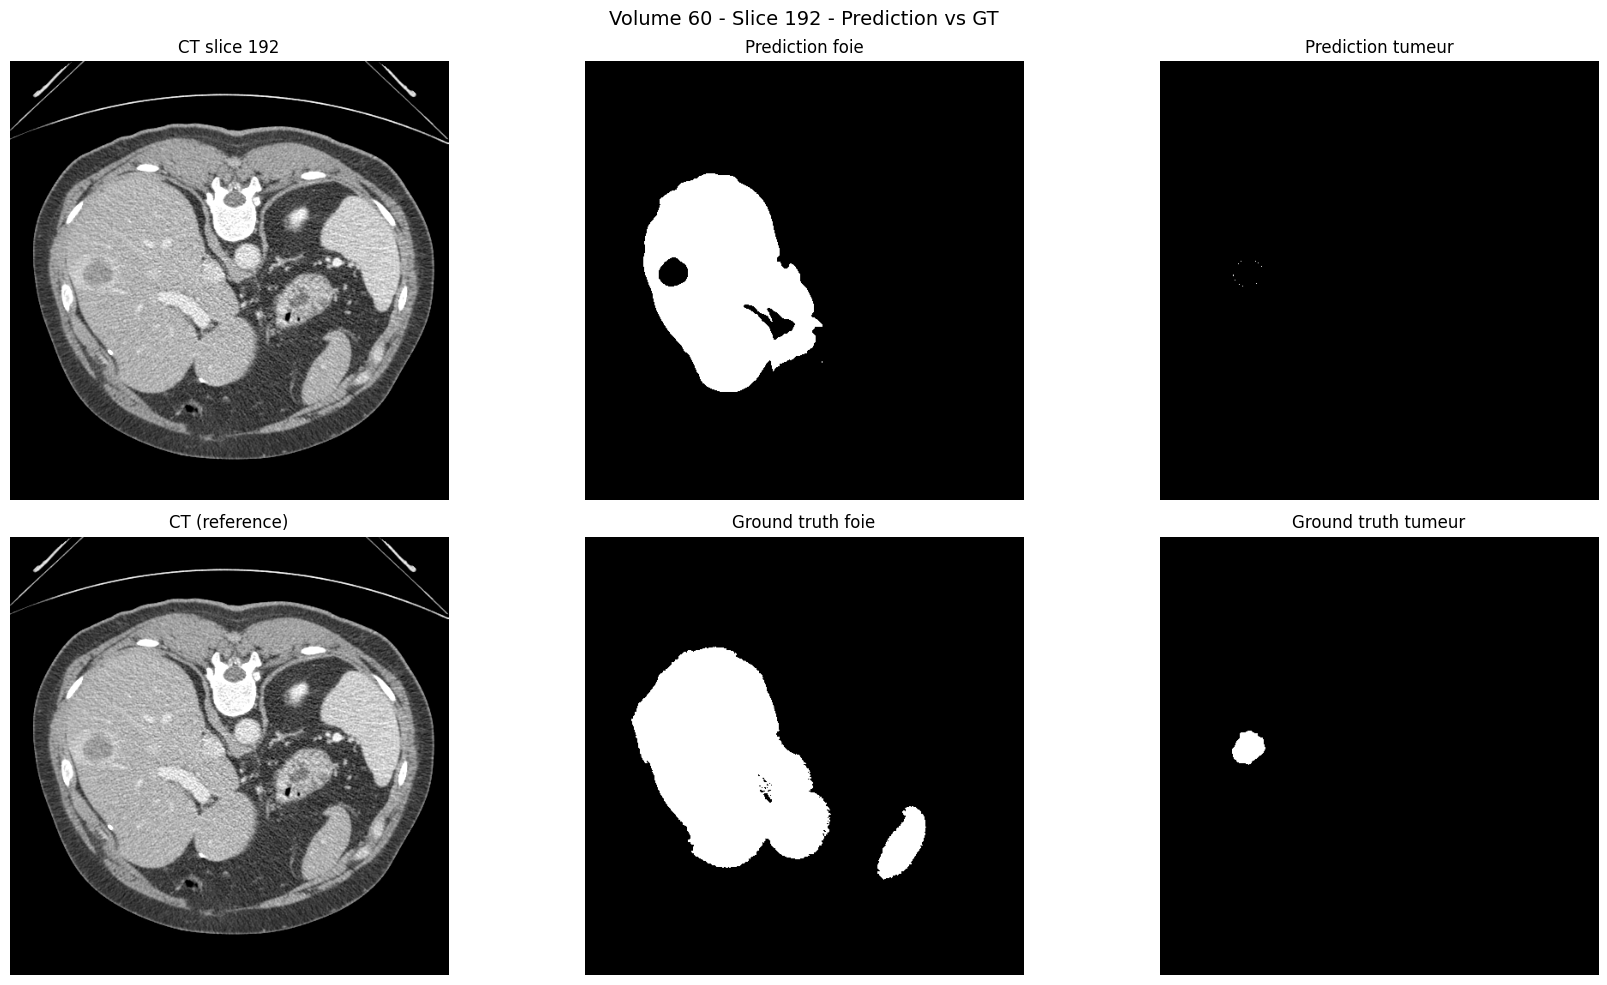

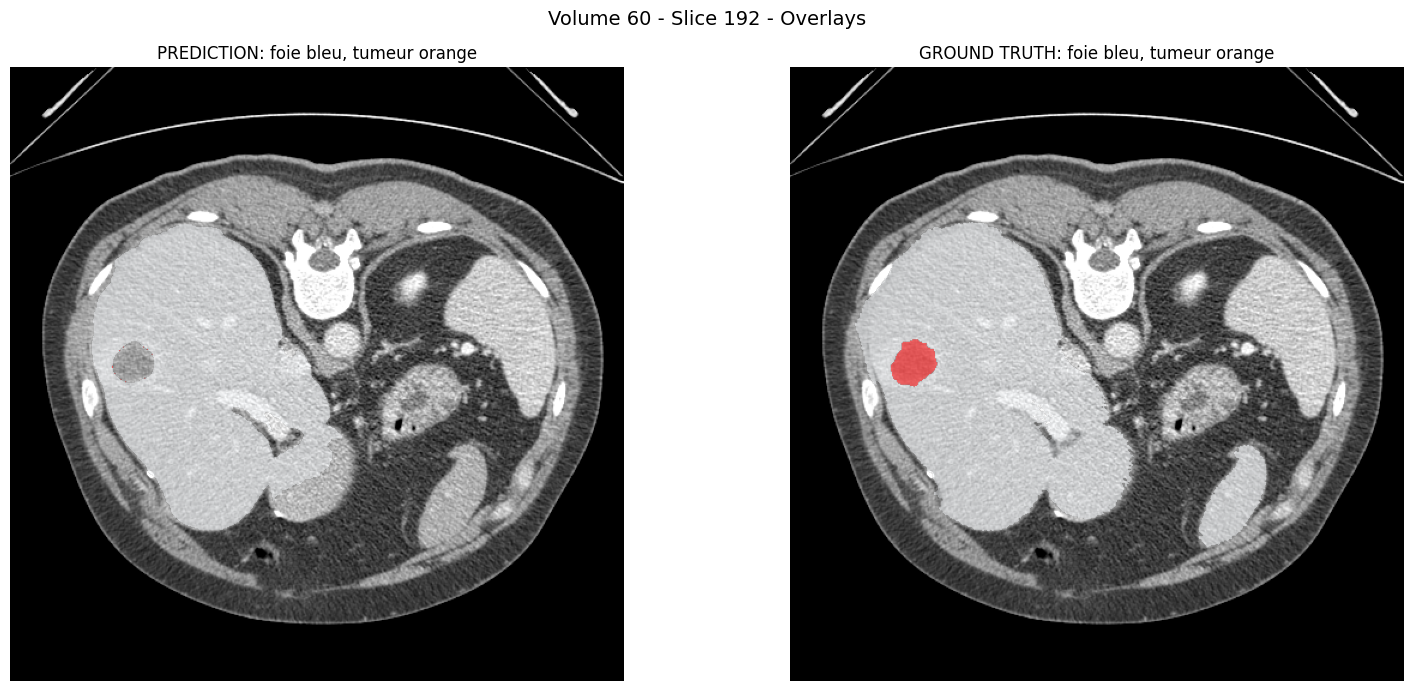

In [16]:
import matplotlib.pyplot as plt
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))


TARGET_VOLUME = 60
TARGET_SLICE  = 192

# Charger et predire
result = predict_on_volume(
    df.iloc[TARGET_VOLUME]['volume_path'],
    df.iloc[TARGET_VOLUME]['segmentation_path'],
    pipeline, device
)

# Donnees
volume_normalized = result['volume_norm']
pred_liver_vol    = result['pred_liver']
pred_tumor_vol    = result['pred_tumor']
seg_data          = result['seg']
best_z            = TARGET_SLICE

ct_slice         = volume_normalized[:, :, best_z]
liver_pred_slice = pred_liver_vol[:, :, best_z]
tumor_pred_slice = pred_tumor_vol[:, :, best_z]
seg_slice        = seg_data[:, :, best_z]
liver_gt_slice   = (seg_slice >= 1).astype(np.uint8)
tumor_gt_slice   = (seg_slice == 2).astype(np.uint8)

print(f"Volume {TARGET_VOLUME} | Slice {best_z}")
print(f"Dice foie: {result['dice_liver']:.4f} | Dice tumeur: {result['dice_tumor']:.4f}")
print(f"Pixels foie pred: {int(liver_pred_slice.sum())} | GT: {int(liver_gt_slice.sum())}")
print(f"Pixels tumeur pred: {int(tumor_pred_slice.sum())} | GT: {int(tumor_gt_slice.sum())}")

# Figure 1: Prediction vs Ground Truth
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].imshow(ct_slice.T, cmap='gray', origin='lower')
axes[0, 0].set_title(f'CT slice {best_z}')
axes[0, 0].axis('off')

axes[0, 1].imshow(liver_pred_slice.T, cmap='gray', origin='lower', vmin=0, vmax=1)
axes[0, 1].set_title('Prediction foie')
axes[0, 1].axis('off')

axes[0, 2].imshow(tumor_pred_slice.T, cmap='gray', origin='lower', vmin=0, vmax=1)
axes[0, 2].set_title('Prediction tumeur')
axes[0, 2].axis('off')

axes[1, 0].imshow(ct_slice.T, cmap='gray', origin='lower')
axes[1, 0].set_title('CT (reference)')
axes[1, 0].axis('off')

axes[1, 1].imshow(liver_gt_slice.T, cmap='gray', origin='lower', vmin=0, vmax=1)
axes[1, 1].set_title('Ground truth foie')
axes[1, 1].axis('off')

axes[1, 2].imshow(tumor_gt_slice.T, cmap='gray', origin='lower', vmin=0, vmax=1)
axes[1, 2].set_title('Ground truth tumeur')
axes[1, 2].axis('off')

plt.suptitle(f'Volume {TARGET_VOLUME} - Slice {best_z} - Prediction vs GT', fontsize=14)
plt.tight_layout()
plt.show()

# Figure 2: Overlays
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(ct_slice.T, cmap='gray', origin='lower')
axes[0].imshow(np.ma.masked_where(liver_pred_slice.T == 0, liver_pred_slice.T), cmap='Blues', alpha=0.35, origin='lower')
axes[0].imshow(np.ma.masked_where(tumor_pred_slice.T == 0, tumor_pred_slice.T), cmap='autumn', alpha=0.55, origin='lower')
axes[0].set_title('PREDICTION: foie bleu, tumeur orange')
axes[0].axis('off')

axes[1].imshow(ct_slice.T, cmap='gray', origin='lower')
axes[1].imshow(np.ma.masked_where(liver_gt_slice.T == 0, liver_gt_slice.T), cmap='Blues', alpha=0.35, origin='lower')
axes[1].imshow(np.ma.masked_where(tumor_gt_slice.T == 0, tumor_gt_slice.T), cmap='autumn', alpha=0.55, origin='lower')
axes[1].set_title('GROUND TRUTH: foie bleu, tumeur orange')
axes[1].axis('off')

plt.suptitle(f'Volume {TARGET_VOLUME} - Slice {best_z} - Overlays', fontsize=14)
plt.tight_layout()
plt.show()

#  SECTION 14: RÉSULTATS ET GRAPHIQUES
Courbes d'entraînement (Loss, Accuracy, Dice), Matrice de Confusion, et Metriques finales

In [24]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [10]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# ===== GRAPHIQUES COMPLETS - COURBES PAR EPOCH + CONFUSION MATRIX =====
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Charger history depuis checkpoint
if not history["train_loss"]:
    ckpt    = torch.load(CHECKPOINT_PATH, map_location=device)
    history = ckpt.get("history", {})

epochs = range(1, len(history["train_loss"]) + 1)

# FIGURE 1: Courbe Loss
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(epochs, history["train_loss"], "b-o", linewidth=2, markersize=5, label="Train Loss")
ax.plot(epochs, history["val_loss"],   "r-o", linewidth=2, markersize=5, label="Val Loss")
ax.set_title("Courbe des pertes", fontsize=14, fontweight="bold")
ax.set_xlabel("Epochs")
ax.set_ylabel("Loss")
ax.legend(fontsize=11)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig("/workspace/curve_loss.png", dpi=150, bbox_inches="tight")
plt.show()

# FIGURE 2: Courbe Accuracy
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(epochs, history["train_acc"], "b-o", linewidth=2, markersize=5, label="Train Acc")
ax.plot(epochs, history["val_acc"],   "r-o", linewidth=2, markersize=5, label="Val Acc")
ax.set_title("Courbe des precisions", fontsize=14, fontweight="bold")
ax.set_xlabel("Epochs")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=11)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig("/workspace/curve_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

# FIGURE 3: Courbe Dice Foie
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(epochs, history["train_dice_liver"], "b-o", linewidth=2, markersize=5, label="Train Dice Foie")
ax.plot(epochs, history["val_dice_liver"],   "r-o", linewidth=2, markersize=5, label="Val Dice Foie")
ax.set_title("Courbe Dice - Foie", fontsize=14, fontweight="bold")
ax.set_xlabel("Epochs")
ax.set_ylabel("Dice Score")
ax.set_ylim(0, 1)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig("/workspace/curve_dice_liver.png", dpi=150, bbox_inches="tight")
plt.show()

# FIGURE 4: Courbe Dice Tumeur
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(epochs, history["train_dice_tumor"], "b-o", linewidth=2, markersize=5, label="Train Dice Tumeur")
ax.plot(epochs, history["val_dice_tumor"],   "r-o", linewidth=2, markersize=5, label="Val Dice Tumeur")
ax.set_title("Courbe Dice - Tumeur", fontsize=14, fontweight="bold")
ax.set_xlabel("Epochs")
ax.set_ylabel("Dice Score")
ax.set_ylim(0, 1)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig("/workspace/curve_dice_tumor.png", dpi=150, bbox_inches="tight")
plt.show()

# FIGURE 5: 4 courbes ensemble
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plots = [
    (axes[0,0], "train_loss",       "val_loss",       "Loss",        "Loss"),
    (axes[0,1], "train_acc",        "val_acc",        "Accuracy",    "Accuracy"),
    (axes[1,0], "train_dice_liver", "val_dice_liver", "Dice Foie",   "Dice"),
    (axes[1,1], "train_dice_tumor", "val_dice_tumor", "Dice Tumeur", "Dice"),
]
for ax, tk, vk, title, ylabel in plots:
    ax.plot(epochs, history[tk], "b-o", linewidth=2, markersize=5, label="Train")
    ax.plot(epochs, history[vk], "r-o", linewidth=2, markersize=5, label="Val")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epochs")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.4)
plt.suptitle("Courbes entrainement - UNet 2.5D LiTS", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("/workspace/all_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# FIGURE 6: Matrice de confusion sur Val set
print("Calcul matrice de confusion...")
all_preds, all_targets = [], []
model.eval()
with torch.no_grad():
    for batch in tqdm(val_loader_fast, desc="Confusion matrix"):
        images = batch["image"].to(device, non_blocking=True)
        target = batch["target"].to(device, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=use_amp):
            outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        all_preds.append(preds.cpu().numpy().flatten())
        all_targets.append(target.cpu().numpy().flatten())

all_preds   = np.concatenate(all_preds)
all_targets = np.concatenate(all_targets)
cm = confusion_matrix(all_targets, all_preds, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Background", "Foie", "Tumeur"],
            yticklabels=["Background", "Foie", "Tumeur"],
            ax=ax, linewidths=0.5)
ax.set_xlabel("Predits", fontsize=12)
ax.set_ylabel("Reels", fontsize=12)
ax.set_title("Matrice de Confusion - Val Set", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("/workspace/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# FIGURE 7: Barplot metriques test (si Cell 11 executee)
try:
    metric_keys   = ["dice", "iou", "precision", "recall", "f1"]
    metric_labels = ["Dice", "IoU", "Precision", "Recall", "F1"]
    liver_means = [np.mean(metrics_liver[k]) for k in metric_keys]
    tumor_means = [np.mean(metrics_tumor[k]) for k in metric_keys]
    liver_stds  = [np.std(metrics_liver[k])  for k in metric_keys]
    tumor_stds  = [np.std(metrics_tumor[k])  for k in metric_keys]
    x = np.arange(len(metric_keys))
    w = 0.35
    fig, ax = plt.subplots(figsize=(12, 6))
    b1 = ax.bar(x-w/2, liver_means, w, yerr=liver_stds, label="Foie",   color="steelblue", capsize=4)
    b2 = ax.bar(x+w/2, tumor_means, w, yerr=tumor_stds, label="Tumeur", color="tomato",    capsize=4)
    ax.set_xticks(x)
    ax.set_xticklabels(metric_labels, fontsize=12)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Score", fontsize=12)
    ax.set_title("Metriques Test Set - Foie vs Tumeur", fontsize=14, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, axis="y", alpha=0.4)
    for bar in list(b1)+list(b2):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
                f"{bar.get_height():.3f}", ha="center", fontsize=9, fontweight="bold")
    plt.tight_layout()
    plt.savefig("/workspace/metrics_barplot.png", dpi=150, bbox_inches="tight")
    plt.show()
except Exception as e:
    print(f"Executer Cell 11 d abord pour les metriques test: {e}")

print("Tous les graphiques sauvegardes dans /kaggle/working/")


START: 03:34:05


NameError: name 'history' is not defined

In [5]:
# ===== CELL SETUP WINDOWS: DATASET + PATHS =====
from pathlib import Path
import glob
import os
import pandas as pd

DATASET_ROOT = Path(r"C:/Users/neifa/Documents/ENETCOM/2IDSD/PFA/dataset")
SEG_DIR = DATASET_ROOT / "segmentations"
VOLUME_DIRS = [f"volume_pt{i}" for i in [1, 2, 3, 4, 5, 6, 8]]

rows = []
for d in VOLUME_DIRS:
    folder = DATASET_ROOT / d
    if not folder.exists():
        continue
    for volume_file in glob.glob(str(folder / "volume-*.nii")):
        volume_num = Path(volume_file).stem.replace("volume-", "")
        seg_file = SEG_DIR / f"segmentation-{volume_num}.nii"
        if seg_file.exists():
            rows.append({
                "volume_path": volume_file,
                "segmentation_path": str(seg_file),
                "volume_id": int(volume_num),
            })

if not rows:
    raise FileNotFoundError(f"Aucune paire volume/seg trouvée sous {DATASET_ROOT}")

df = pd.DataFrame(rows).sort_values("volume_id").reset_index(drop=True)

# Chemins checkpoints locaux (si inexistants, le pipeline utilisera le modèle courant)
CHECKPOINT_DIR = Path(r"C:/Users/neifa/Documents/ENETCOM/2IDSD/PFA/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = str(CHECKPOINT_DIR / "best_model.pth")

print(f"✅ Dataset indexé: {len(df)} volumes")
print(f"✅ BEST_MODEL_PATH: {BEST_MODEL_PATH}")
print(df.head())

✅ Dataset indexé: 131 volumes
✅ BEST_MODEL_PATH: C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\checkpoints\best_model.pth
                                         volume_path  \
0  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...   
1  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...   
2  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...   
3  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...   
4  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...   

                                   segmentation_path  volume_id  
0  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...          0  
1  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...          1  
2  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...          2  
3  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...          3  
4  C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dat...          4  
